# Lab 12-07 · Output Stages and Power Amplifiers

Companion to [chapter 12-07](../../chapters/12-07-output-stages.md). Four parts: efficiency and dissipation against amplitude for class A, B and D; crossover distortion with and without feedback and with class AB bias; class AB currents; and a thermal-runaway simulation. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

N = 4096
SIN = np.sin(2 * math.pi * (np.arange(N) + 0.5) / N)
VT = 0.025852

## Part 1 · Efficiency and dissipation against amplitude

±15 V supplies, 8 Ω load. Class A biased for full swing ($I_Q = V_{CC}/R_L$); ideal class B; and a class D model with two 85 mΩ switches in the path and 2.5 W of fixed loss (BTL from 30 V, so the same ±15 V swing).

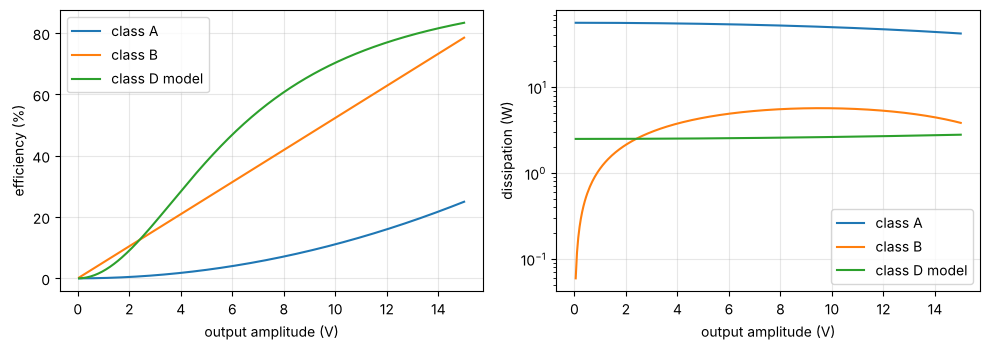

class B worst dissipation 5.699 W at 9.55 V (2Vcc/pi = 9.549 V)


In [2]:
Vcc, RL = 15.0, 8.0
amps = np.linspace(0.05, 15, 300)
def averages(Vop):
    vo = Vop * SIN
    PL = np.mean(vo ** 2 / RL)
    PS_A = 2 * Vcc * (Vcc / RL)
    PS_B = Vcc * np.mean(np.abs(vo) / RL)
    PS_D = PL + np.mean((vo / RL) ** 2) * 0.17 + 2.5
    return PL, PS_A, PS_B, PS_D
res = np.array([averages(a) for a in amps])
PL = res[:, 0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k, lab in ((1, 'class A'), (2, 'class B'), (3, 'class D model')):
    ax[0].plot(amps, 100 * PL / res[:, k], label=lab)
    ax[1].plot(amps, res[:, k] - PL, label=lab)
ax[0].set_xlabel('output amplitude (V)'); ax[0].set_ylabel('efficiency (%)'); ax[0].legend(); ax[0].grid(True, alpha=0.3)
ax[1].set_xlabel('output amplitude (V)'); ax[1].set_ylabel('dissipation (W)'); ax[1].set_yscale('log'); ax[1].legend(); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
k = np.argmax(res[:, 2] - PL)
print(f"class B worst dissipation {res[k, 2] - PL[k]:.3f} W at {amps[k]:.2f} V (2Vcc/pi = {2 * Vcc / math.pi:.3f} V)")

## Part 2 · Crossover distortion

A ±0.6 V dead band, open, inside a loop with $A$ = 10⁴, and with class AB bias modelled by exponential devices idling at 20 mA (output driven into 8 Ω).

In [3]:
def dead(x, d=0.6):
    return np.where(x > d, x - d, np.where(x < -d, x + d, 0.0))
def thd(y):
    F = np.abs(np.fft.rfft(y)) / len(y) * 2
    return math.sqrt(np.sum(F[2:] ** 2)) / F[1] if F[1] > 0 else float('inf')   # inf: no output at all
def loop(vin, A=1e4, d=0.6):
    x = A * vin
    return np.where(x > d, (x - d) / (1 + A), np.where(x < -d, (x + d) / (1 + A), 0.0))
IS = 1e-13; VBB = 2 * VT * math.log(20e-3 / IS)
def ab(vin):
    out = []
    for x in vin:   # bases at x +/- VBB/2; solve the output node with an 8-ohm load
        f = lambda vo: IS * math.exp((x + VBB / 2 - vo) / VT) - IS * math.exp((vo - x + VBB / 2) / VT) - vo / 8
        out.append(brentq(f, x - 1.5, x + 1.5, xtol=1e-14))
    return np.array(out)
for A_in in (0.1, 1.0, 10.0):
    print(f"{A_in:5.1f} V: open {100 * thd(dead(A_in * SIN)):8.4f}%   loop {100 * thd(loop(A_in * SIN)):10.6f}%   class AB {100 * thd(ab(A_in * SIN)):8.4f}%")

  0.1 V: open      inf%   loop   0.036959%   class AB   0.0249%
  1.0 V: open  46.5311%   loop   0.003693%   class AB   0.5174%


 10.0 V: open   3.7308%   loop   0.000369%   class AB   0.3221%


## Part 3 · Class AB currents

From the translinear relation $i_Ni_P = I_Q^2$ with $I_Q$ = 20 mA.

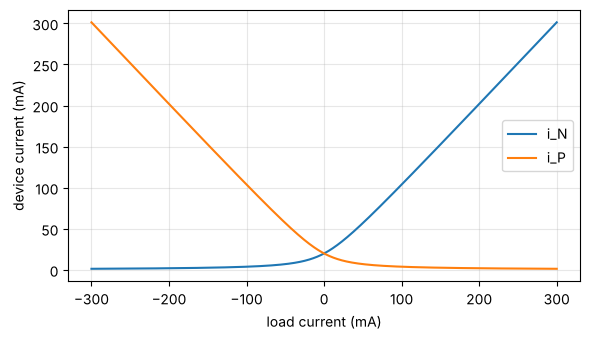

at 100 mA: i_N = 103.85 mA, i_P = 3.852 mA


In [4]:
IQ = 20e-3
iL = np.linspace(-0.3, 0.3, 601)
iN = iL / 2 + np.sqrt(iL ** 2 / 4 + IQ ** 2); iP = iN - iL
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(iL * 1e3, iN * 1e3, label='i_N'); ax.plot(iL * 1e3, iP * 1e3, label='i_P')
ax.set_xlabel('load current (mA)'); ax.set_ylabel('device current (mA)'); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
print(f"at 100 mA: i_N = {iN[400] * 1e3:.2f} mA, i_P = {iP[400] * 1e3:.3f} mA")

## Part 4 · Thermal runaway

A transistor at $V_{CE}$ = 15 V with fixed base voltage, biased at 100 mA at 25 °C, total θ = 12 °C/W and a thermal time constant of 10 s. Each step: solve the current at the present temperature, then let the temperature relax toward $T_A + \theta P$. Compare $R_E$ = 0 (loop gain 1.39) with $R_E$ = 0.47 Ω (0.49).

R_E = 0.0: after 48 s, T = 189.4 C, I = 10071 mA
R_E = 0.47: after 300 s, T = 43.0 C, I = 100 mA


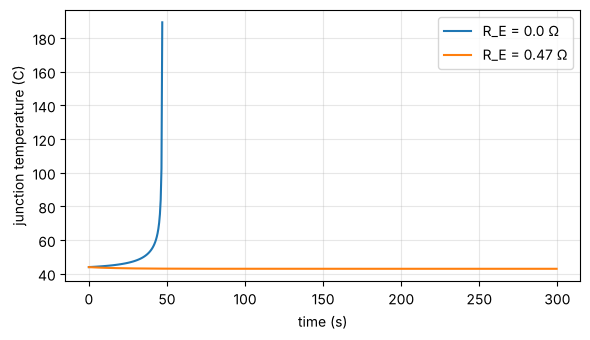

In [5]:
def run(RE, steps=600, dt=0.5, tau=10.0):
    VB = VT * math.log(0.1 / 1e-14) + 0.1 * RE
    T0 = 25.0 + 15 * 0.1 * 12           # equilibrium temperature at 100 mA
    T, out = T0 + 1.0, []               # start 1 C above it
    for _ in range(steps):
        I = brentq(lambda i: VT * math.log(i / 1e-14) - 0.002 * (T - T0) + i * RE - VB, 1e-6, 1e12)
        T += dt / tau * (25 + 12 * 15 * I - T)
        out.append((I, T))
        if T > 200 or I > 5: break
    return np.array(out)
fig, ax = plt.subplots(figsize=(6, 3.5))
for RE in (0.0, 0.47):
    r = run(RE)
    ax.plot(np.arange(len(r)) * 0.5, r[:, 1], label=f'R_E = {RE} Ω')
    print(f"R_E = {RE}: after {len(r) * 0.5:.0f} s, T = {r[-1, 1]:.1f} C, I = {r[-1, 0] * 1e3:.0f} mA")
ax.set_xlabel('time (s)'); ax.set_ylabel('junction temperature (C)'); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Discussion.** Both runs start 1 °C above the equilibrium for 100 mA. Without degeneration (loop gain 1.39) the disturbance grows roughly as $e^{(L-1)t/	au}$ until the junction passes 200 °C; with 0.47 Ω (loop gain 0.49) it decays and the transistor settles back. The equilibrium exists in both cases: what differs is whether it is stable.